# SHS generation + analysis

In [89]:
# Sequence & structure
PROTEIN_SEQ = "ACDEFGHIKLMNPQRSTVWYACDEFGHIKLMNPQRSTVWY"
PAIRS = [
    # --- Cluster 1: Local Alpha-Helix like (i, i+3 or i+4) ---
    [0, 3, 0.4], [1, 4, 0.4], [2, 5, 0.4], [3, 6, 0.4], [4, 7, 0.4],
    
    # --- Cluster 2: Transitive Set (A->B, B->C, A->C) ---
    # 10 is close to 15, 15 is close to 20, 10 is also close to 20
    [10, 15, 1.0], 
    [15, 20, 1.0], 
    # [10, 20, 0.8], 
    
    # --- Cluster 3: Beta-sheet like (Long range) ---
    # Connecting the first half of the protein to the second half
    [2, 38, 1.0], [3, 37, 1.0], [4, 36, 1.0], [5, 35, 1.0],
    
    # --- Cluster 4: Tight Loop/Turn ---
    [12, 13, 0.2], [13, 14, 0.2], [12, 14, 0.3],
    
    # --- Cluster 5: Dispersed Tertiary Contacts ---
    [8, 25, 0.7], [9, 26, 0.7], [11, 30, 0.9], [17, 33, 0.5], [18, 34, 0.5],
    
    # --- Cluster 6: C-terminal local clustering ---
    [35, 36, 0.4], [36, 37, 0.4], [37, 38, 0.4], [38, 39, 0.4]
]

# Converting to string format as requested in your snippet
PAIRS_STR = str(PAIRS)
MUTATION_RATES = None

# MSA size / reproducibility
N = 10000
SEED = 42

# Mutation parameters
MUTATION_RATE_PAIRED = 0.5
MUTATION_RATE_UNPAIRED = 0.4
PAIR_MUTATION_APPROACH = "covariance"  # covariance | none

# insertions / deletions - paired
STEM_SINGLE_INSERTION_PROB  = 0.05
STEM_LONG_INSERTION_PROB    = 0.01
STEM_SINGLE_DELETION_PROB   = 0.1
STEM_PAIR_DELETION_PROB     = 0.2
STEM_MAX_INSERTION_FRACTION = 0.2

# insertions / deletions - unpaired
LOOP_SINGLE_INSERTION_PROB = 0.1
LOOP_SINGLE_DELETION_PROB  = 0.3
LOOP_LONG_INSERTION_PROB   = 0.1
LOOP_LONG_DELETION_PROB    = 0.05
LOOP_MAX_INSERTION_FRACTION = 0.2
LOOP_MAX_DELETION_FRACTION  = 0.1


## Setup

In [90]:
import importlib
import sys
from pathlib import Path

%matplotlib inline

_roots = (Path.cwd(), *Path.cwd().parents)
REPO_ROOT = next((p for p in _roots if (p / "SHS-Generator-Protein" / "shs_generator.py").exists()), None)
if REPO_ROOT is None:
    raise FileNotFoundError("Could not find the SyntheticEvolution repository root.")
SHS_DIR = (REPO_ROOT / "SHS-Generator-Protein").resolve()
ANALYZER_DIR = (REPO_ROOT / "analysis" / "SHS-Analyzer-Protein").resolve()
for module_dir in (SHS_DIR, ANALYZER_DIR):
    if str(module_dir) not in sys.path:
        sys.path.insert(0, str(module_dir))

import pair_map, generator_config, json_generator, shs_generator, shs_analyzer
importlib.reload(pair_map); importlib.reload(generator_config)
importlib.reload(json_generator); importlib.reload(shs_generator)
importlib.reload(shs_analyzer)

print("SHS-Generator dir:", SHS_DIR)
print("SHS-Analyzer dir:", ANALYZER_DIR)

SHS-Generator dir: /home/tyler/Uni/bachelorarbeit/SyntheticEvolution/SHS-Generator-Protein
SHS-Analyzer dir: /home/tyler/Uni/bachelorarbeit/SyntheticEvolution/analysis/SHS-Analyzer-Protein


## Generate the SHS

In [91]:
structure_input = shs_generator.parse_json(PAIRS) if isinstance(PAIRS, str) else PAIRS
per_position_rates = shs_generator.parse_json(MUTATION_RATES) if isinstance(MUTATION_RATES, str) else MUTATION_RATES
pair_map = generator_config.build_pair_map(
    PROTEIN_SEQ, structure_input,
    mutation_rate_paired=MUTATION_RATE_PAIRED,
    mutation_rate_unpaired=MUTATION_RATE_UNPAIRED,
    mutation_rates=per_position_rates,
)

# Only global algorithm settings belong in MutationParameters.
parameters = generator_config.MutationParameters(
    N=N,
    pair_mutation_approach=PAIR_MUTATION_APPROACH,
    stem_single_insertion_prob=STEM_SINGLE_INSERTION_PROB,
    stem_long_insertion_prob=STEM_LONG_INSERTION_PROB,
    stem_single_deletion_prob=STEM_SINGLE_DELETION_PROB,
    stem_pair_deletion_prob=STEM_PAIR_DELETION_PROB,
    stem_max_insertion_fraction=STEM_MAX_INSERTION_FRACTION,
    loop_single_insertion_prob=LOOP_SINGLE_INSERTION_PROB,
    loop_single_deletion_prob=LOOP_SINGLE_DELETION_PROB,
    loop_long_insertion_prob=LOOP_LONG_INSERTION_PROB,
    loop_long_deletion_prob=LOOP_LONG_DELETION_PROB,
    loop_max_insertion_fraction=LOOP_MAX_INSERTION_FRACTION,
    loop_max_deletion_fraction=LOOP_MAX_DELETION_FRACTION,
)
generator = shs_generator.MsaGenerator(parameters, seed=SEED)
msa = generator.generate(PROTEIN_SEQ, pair_map)

# JSON construction is separate from generation. This notebook does not save it.
generated_json = json_generator.build_input_json(
    PROTEIN_SEQ, msa, name="notebook_protein", model_seeds=[1],
)
print("Generated", len(msa), "MSA rows for", len(PROTEIN_SEQ), "residues")


Generated 10000 MSA rows for 40 residues


## Analyze & render

Query length: 40  |  MSA rows: 10000  |  covariance shape: (40, 40)
ACDEFGHIKLMNPQRSTVWYACDEFGHIKLMNPQRSTVWY
-C-EgqmkfhmeLESI-EMNPCRSTVWeVACFHn-GY-K-LaNc-iCTSTR-H
AWDkrlqvCF-VDKLMSNW-SHqV--A---FGmGICI-kWEQq-W-EPY
ACDEKKYAK-MVIIMSQ-NYACfrgckD-aFidcaGf-HKLMNP-MQTWWRm
ICKEKWSETLCNC-YQTCyslciWi-AC-F-RKI--nMGPMv-CTVWY
GTVEAGWIKLM--QRSIclnnqfitE--C-DQ-YHI-Efdlm--PQRST-WvY
AsCKEFRSIH-WFPNCRVSWYF-mknfsDF-RHYWLkagklmnW-t-RMdCQVpW-
-KCRA-HNKETN-CNSTmdVWQplkyfmd--DEFGT-KGMS-QRSHVWT
CEDTAVKT-Lp--PWR-PHWqTlHC-p--GHrnnY-g-QLrdm--LSHY-Ydrrt
WDKEMGaHY-LMFNSQSpTyslvaVWVAmvnf-mstDEF-AI--TeharmqfI-QRSWVIY
ACGSFY--T-M-T-RS--WFQeP-E-P-IK--fNS-RCQVPY


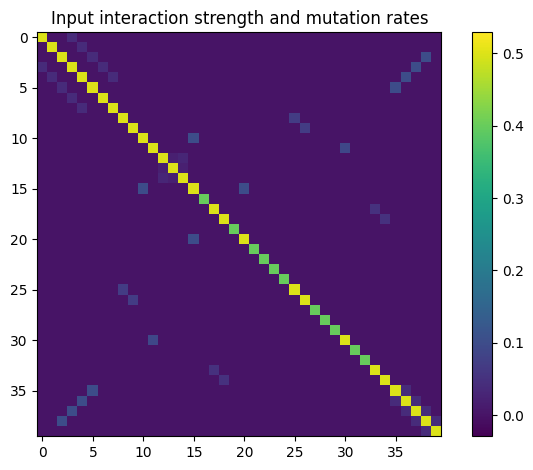

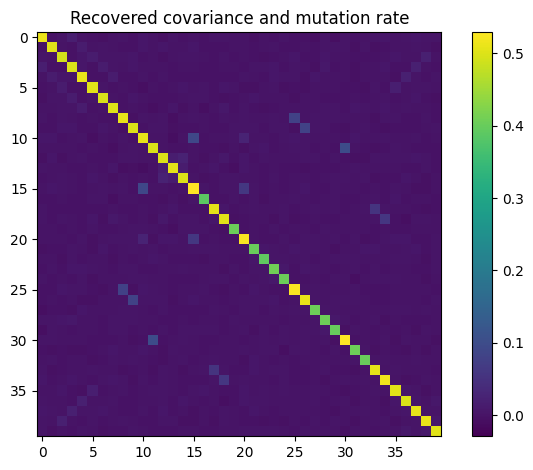

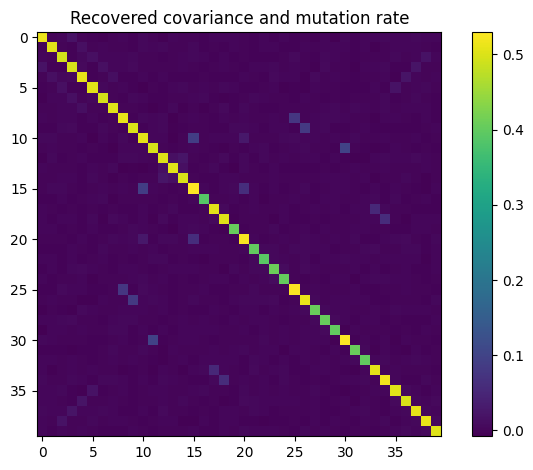

In [92]:
import json
import numpy as np

data = shs_analyzer.MsaData.from_text(json.dumps(generated_json), pairs=pair_map)
feat = shs_analyzer.Features(data)

print(f"Query length: {len(data.seq)}  "
   f"|  MSA rows: {data.aligned.shape[0] + 1}  "
   f"|  covariance shape: {feat.covariance.shape}")

print(data.seq)
for row in data.raw[:10]:
    print("".join(row))


expectation = data.pairs._pairs_mat.copy()
expectation[~np.eye(expectation.shape[0], dtype=bool)] *= 0.1
error = expectation - feat.covariance
vmin, vmax = min(error.min(), expectation.max(), feat.covariance.min()), max(error.max(), expectation.max(), feat.covariance.max())
shs_analyzer.plot_covariance(data.seq, expectation, title="Input interaction strength and mutation rates", show_values=False, vmin=vmin, vmax=vmax)
shs_analyzer.plot_covariance(data.seq, feat.covariance, show_values=False, vmin=vmin, vmax=vmax)
_ =shs_analyzer.plot_covariance(data.seq, feat.covariance, show_values=False)



## Covariance per pair

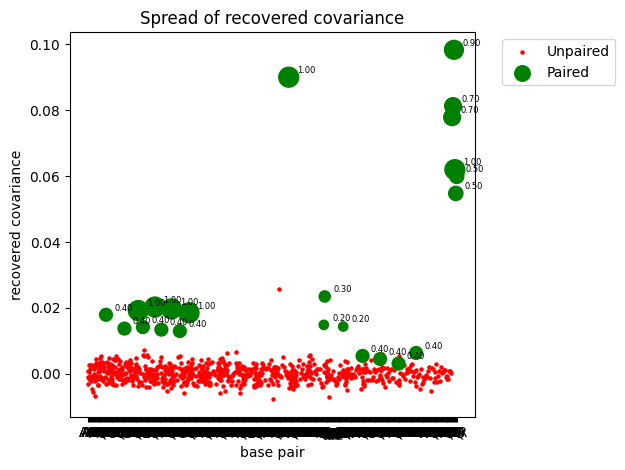

In [93]:
_ = shs_analyzer.plot_covariance_classification(data.seq, feat.covariance, pairs=data.pairs)


## Deletion and Insertion analysis

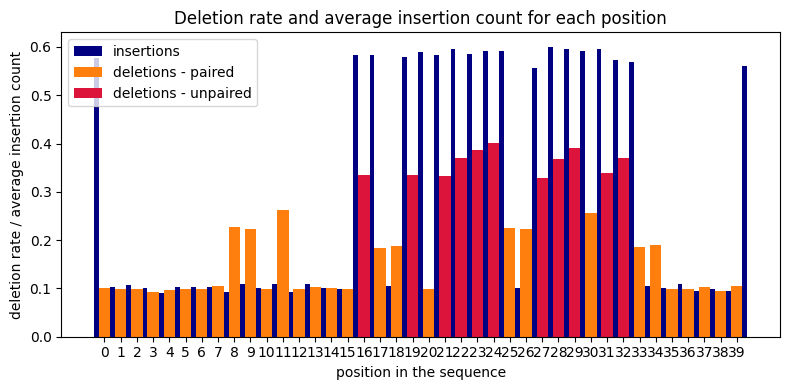

In [94]:
_ = shs_analyzer.plot_deletions_and_insertion(feat.col_deletion_rate, feat.col_insertion_mean, pairs=data.pairs)


## Mutation-rate comparison

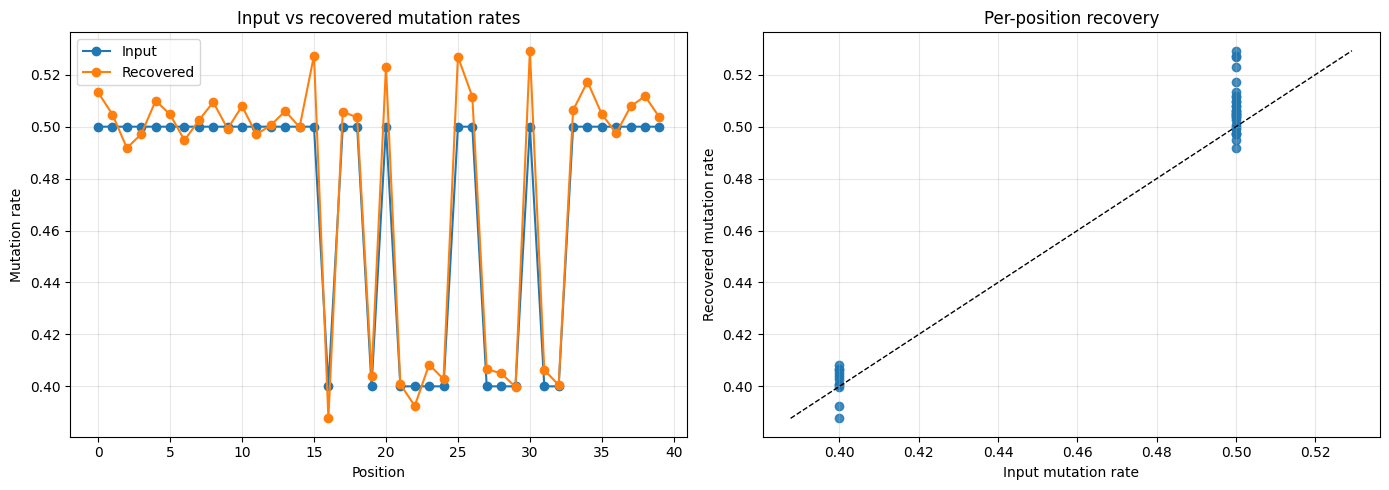

MAE: 0.0079 | RMSE: 0.0108 | Pearson r: 0.9834


In [95]:
# PairMap stores the effective rates, including scalar defaults and overrides.
input_rates = np.array([pair_map.mutation_rate(i) for i in range(len(data.seq))])
output_rates = feat.col_mut_rate
fig, metrics = shs_analyzer.plot_mutation_rate_comparison(input_rates, output_rates)
print(f"MAE: {metrics['mae']:.4f} | RMSE: {metrics['rmse']:.4f} | Pearson r: {metrics['pearson_r']:.4f}")


## Recovered parameters

In [96]:
import pandas as pd

# Show full cell contents so the `detail` strings aren't truncated.
pd.set_option("display.max_colwidth", None)
pd.set_option("display.width", None)

# Known generator input per recovered parameter name (the ground truth each
# estimator tries to reproduce). Extend this as you add estimators.
KNOWN_INPUTS = {
    "n_sequences":            N,
    "mutation_rate_unpaired": MUTATION_RATE_UNPAIRED,
    "mutation_rate_paired":   MUTATION_RATE_PAIRED,
}

report = shs_analyzer.analyze_data(data)


def _fmt_detail(detail):
    # Turn {'unpaired_cols': 14, ...} into a readable "unpaired_cols=14 · ..." line.
    return " · ".join(f"{k}={v}" for k, v in detail.items())


rows = []
for name, est in report.items():
    known = KNOWN_INPUTS.get(name)
    # est.value != est.value is True only for NaN -> no error there.
    error = abs(est.value - known) if (known is not None and est.value == est.value) else None
    rows.append({
        "parameter": name,
        "known":     known,
        "recovered": round(est.value, 4),
        "abs_error": round(error, 4) if error is not None else None,
        "detail":    _fmt_detail(est.detail),
    })

pd.DataFrame(rows).set_index("parameter")


,known,recovered,abs_error,detail
parameter,,,,
n_sequences,10000.0,10000.0000,0.0000,
mutation_rate_unpaired,0.4,0.4013,0.0013,unpaired_cols=11 · structure_known=True
mutation_rate_paired,0.5,0.5073,0.0073,paired_cols=29 · structure_known=True
